# Support Vector Machines and Kernels

![SVM.png](Assets/SVM.png)

# Цели обучения
- Применить метод опорных векторов (SVM) - популярный алгоритм, используемый для задач классификации
- Распознать сходство SVM с логистической регрессией
- Вычислить функцию потерь для SVM
- Применить регуляризацию в SVM и изучить советы по получению нелинейной классификации с помощью SVM

## Введение
В этих упражнениях мы будем использовать набор данных о качестве вина. Этот набор данных содержит различные химические свойства вина, такие как кислотность, сахар, pH и алкоголь. Он также содержит метрику качества (от 3 до 9, где наивысший балл означает лучшее качество) и цвет (красное или белое). Имя файла: `Wine_Quality_Data.csv`.

In [4]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.svm import LinearSVC
from sklearn.svm import SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.svm import SVC
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import MinMaxScaler

try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    print('Intel Extension for Scikit-learn не установлен, работаем с обычным scikit-learn')

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1
* Импорт данных.
* Создайте целевую переменную `y` как колонка 1/0, где 1 означает красное вино.
* Создайте парный график для набора данных.
* Создайте диаграмму столбцов, которая отображает корреляцию между каждым колонкой и `y`.
* Выберите 2 поля с наибольшей корреляцией (используя значения абсолютной корреляции) и создайте `X`.
* Используйте MinMaxScaler для масштабирования `X` Обратите внимание, что вывод будет np.array. Сделайте его снова DataFrame и соответственно переименуйте столбцы.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# файл с данными лежит рядом с ноутбуком
data = pd.read_csv('data/Wine_Quality_Data.csv')
data.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [6]:
# целевая переменная: 1 - красное вино, 0 - белое
y = (data['color'] == 'red').astype(int)
y.value_counts()

color
0    4898
1    1599
Name: count, dtype: int64

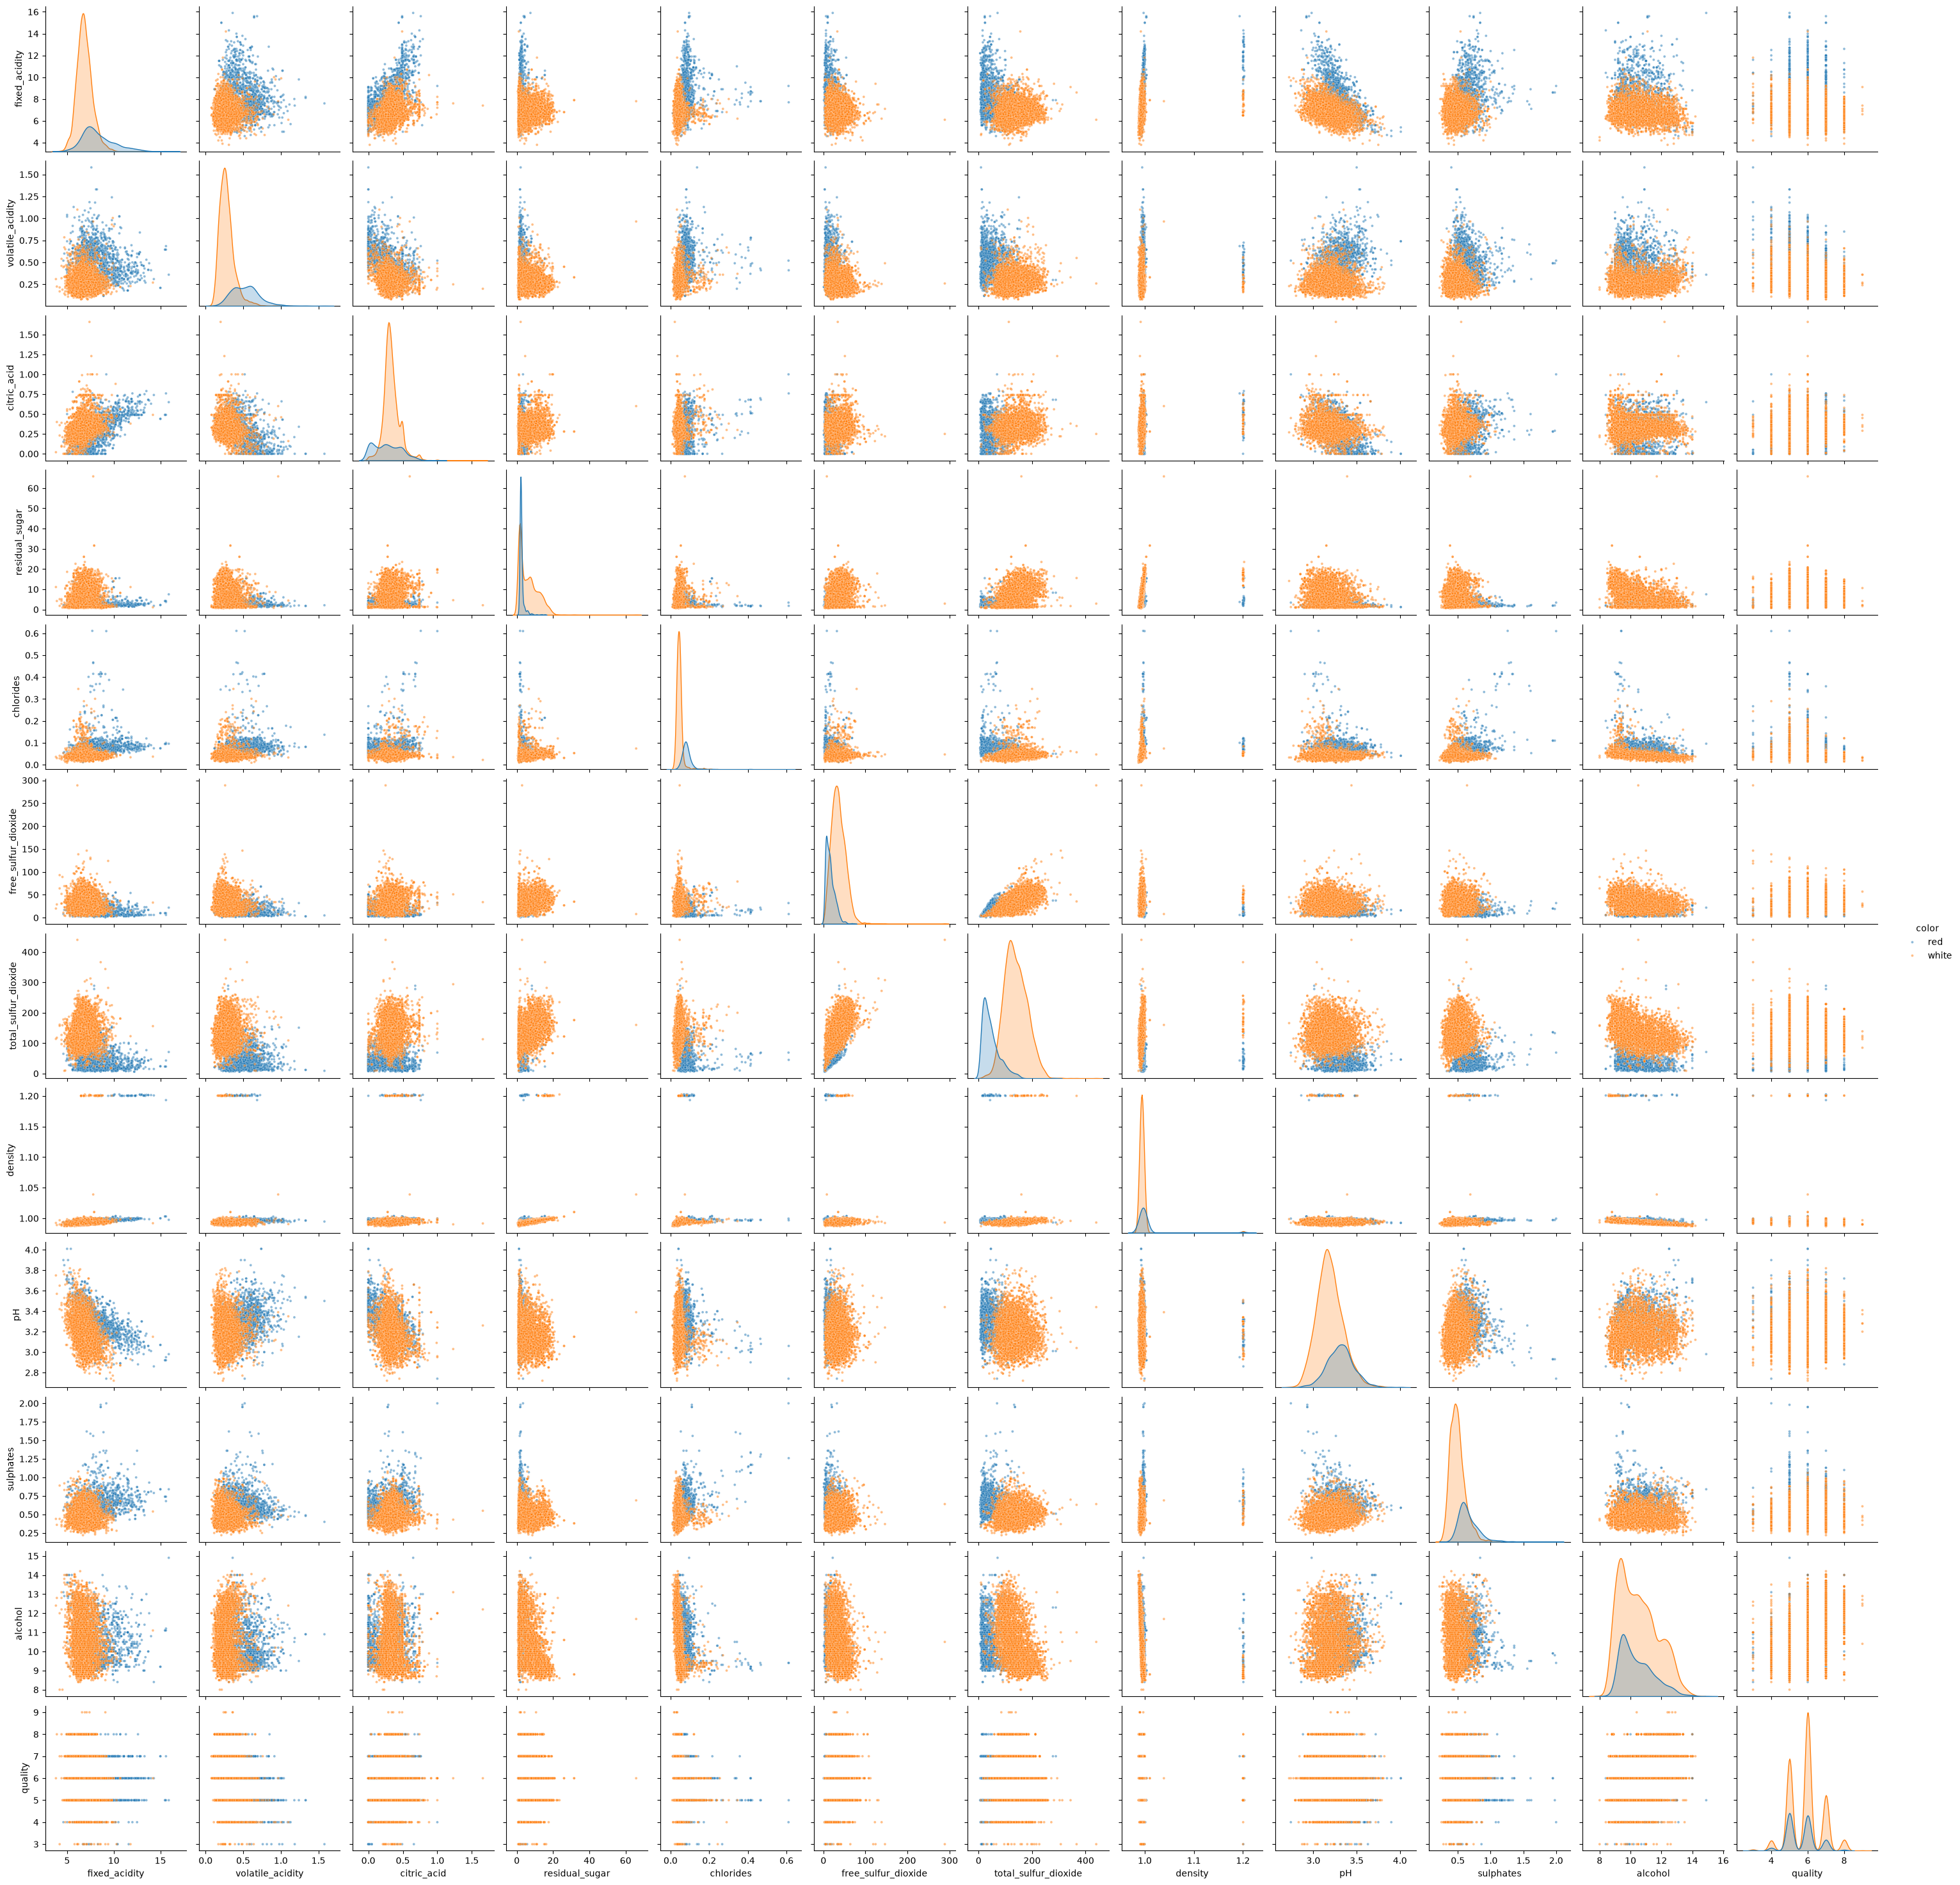

In [7]:
# парный график (цвет точек - тип вина)
sns.pairplot(data, hue='color', plot_kws={'s': 8, 'alpha': 0.5})
plt.show()

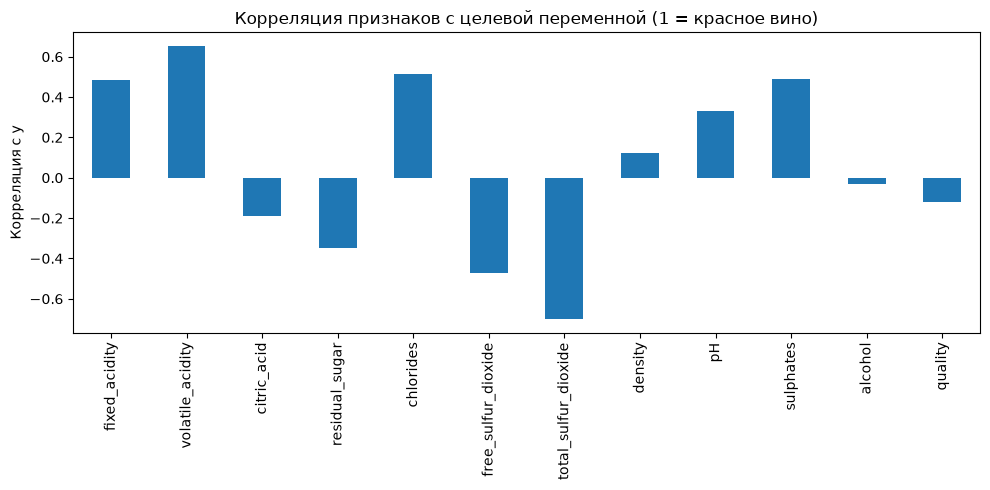

In [8]:
# корреляция каждого признака с y
feature_cols = [x for x in data.columns if x != 'color']
correlations = data[feature_cols].corrwith(y)

correlations.plot(kind='bar', figsize=(10, 5))
plt.ylabel('Корреляция с y')
plt.title('Корреляция признаков с целевой переменной (1 = красное вино)')
plt.tight_layout()
plt.show()

In [9]:
# два признака с наибольшей по модулю корреляцией
top_features = correlations.abs().sort_values(ascending=False).index[:2]
print(list(top_features))

X = data[top_features]

['total_sulfur_dioxide', 'volatile_acidity']


In [10]:
# масштабируем X в диапазон [0, 1]; на выходе np.array, возвращаем DataFrame
mm = MinMaxScaler()
X = pd.DataFrame(mm.fit_transform(X), columns=X.columns)
X.head()

,total_sulfur_dioxide,volatile_acidity
0,0.064516,0.413333
1,0.140553,0.533333
2,0.110599,0.453333
3,0.124424,0.133333
4,0.064516,0.413333


**Что сделано (Вопрос 1):** загрузили данные и создали `y` (1 - красное, 0 - белое). Построили парный график и столбчатую диаграмму корреляций признаков с `y`. Выбрали два признака с наибольшей абсолютной корреляцией - они лучше всего отделяют красное вино от белого. Эти два признака масштабировали с помощью `MinMaxScaler` в диапазон от 0 до 1 и вернули в DataFrame с прежними названиями столбцов.

## Вопрос 2

Цель этого вопроса - посмотреть на границу принятия решения классификатора LinearSVC для данного набора данных. Ознакомьтесь с [этим примером](http://scikit-learn.org/stable/auto_examples/svm/plot_iris.html#sphx-glr-auto-examples-svm-plot-iris-py) в документации sklearn. 

* Установите классификатор линейной векторной машины поддержки на `X` , `y`.
* Выберите 300 образцов из `X`. Получите соответствующее значение `y`. Сохраните их в переменных `X_color` и `y_color`. Это связано с тем, что оригинальный набор данных слишком велик и создает переполненный график.
* Измените `y_color` таким образом, чтобы вместо 1 было указано значение «красный», а вместо 0 - «желтый».
* Рассеянный график для столбцов X_color. Используйте аргумент ключевого слова "color=y_color" для отображения кода цвета.
* Используйте фрагмент кода ниже, чтобы нарисовать поверхность решения в цветной форме.

`python
x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]). T
y_grid_predictions = *[ВАША МОДЕЛЬ]*. predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
`

Не стесняйтесь экспериментировать с различными вариантами параметров для LinearSVC и просмотреть границы принятия решения.

In [11]:
# линейный SVM
linsvc = LinearSVC(random_state=42)
linsvc = linsvc.fit(X, y)

In [12]:
# 300 случайных образцов для графика и соответствующие значения y
X_color = X.sample(300, random_state=45)
y_color = y.loc[X_color.index]

# 1 -> красный, 0 -> жёлтый
y_color = y_color.map({1: 'red', 0: 'yellow'})

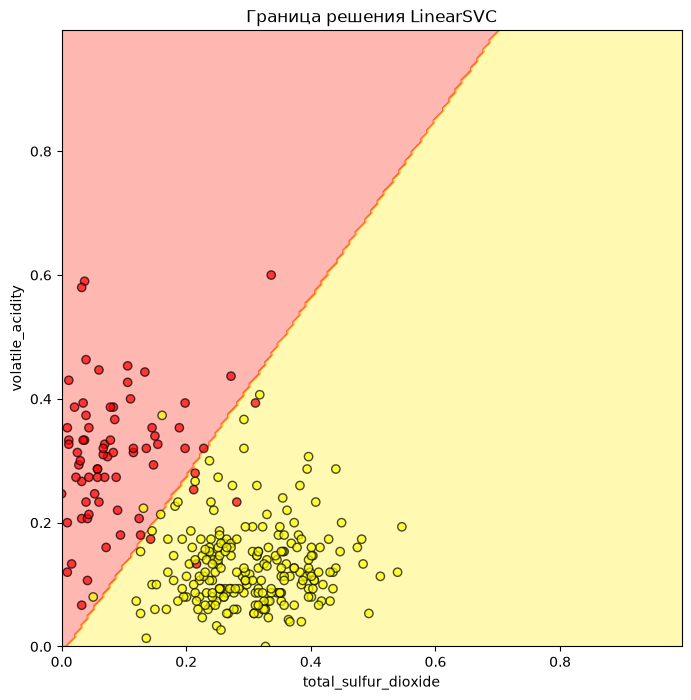

In [13]:
fig, ax = plt.subplots(figsize=(8, 8))

# поверхность решения
x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]).T
X_grid.columns = X.columns   # те же названия столбцов, что и при обучении
y_grid_predictions = linsvc.predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)

# точки выборки
ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, edgecolor='k', alpha=.7)
ax.set(xlabel=X_color.columns[0], ylabel=X_color.columns[1],
       title='Граница решения LinearSVC')
plt.show()

**Что сделано (Вопрос 2):** обучили `LinearSVC` на двух выбранных признаках. Для графика взяли 300 случайных точек (`X_color`, `y_color`) и заменили метки 1/0 на «red»/«yellow». С помощью сетки точек и `predict` закрасили области, где модель предсказывает красное и белое вино, и нанесли на них точки. Граница у линейной модели - прямая линия.

## Вопрос 3

Давайте теперь развернем гауссовское ядро SVC и посмотрим, как изменяется граница решения.

* Объедините фрагменты кода в вопросе 2 в одну функцию, которая использует оценщика `X` и `y`, и создаст окончательный график с границей решения. Этапы:
    <ol>
     <li> подходящая модель
     <li> получить выборку 300 записей из X и соответствующих у
     <li> создать сетку, предсказать, составить график с помощью ax.contourf
     <li> добавить на рассеянный график
    </ol>
* После копирования и вставки кода убедитесь, что готовая функция использует ваш входной `оценщик` а не созданную вами модель LinearSVC.
* Для следующих значений `gamma` создайте Gaussian Kernel SVC и нарисуйте границу решения.  
`gammas = [.5, 1, 2, 10]`
* Удерживая `gamma` постоянную, для различных значений `C`, нарисуйте границу решения. Вы можете попробовать  
`Cs = [.1, 1, 10]>

In [14]:
def plot_decision_boundary(estimator, X, y):
    # 1. обучаем модель
    estimator.fit(X, y)

    # 2. выборка из 300 записей и соответствующие y
    X_color = X.sample(300, random_state=45)
    y_color = y.loc[X_color.index].map({1: 'red', 0: 'yellow'})

    # 3. сетка, предсказание, поверхность решения
    fig, ax = plt.subplots(figsize=(8, 8))
    x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
    xx, yy = np.meshgrid(x_axis, y_axis)
    xx_ravel = xx.ravel()
    yy_ravel = yy.ravel()
    X_grid = pd.DataFrame([xx_ravel, yy_ravel]).T
    X_grid.columns = X.columns
    y_grid_predictions = estimator.predict(X_grid)
    y_grid_predictions = y_grid_predictions.reshape(xx.shape)
    ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)

    # 4. точки выборки
    ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, edgecolor='k', alpha=.7)
    ax.set(xlabel=X.columns[0], ylabel=X.columns[1], title=str(estimator))
    plt.show()

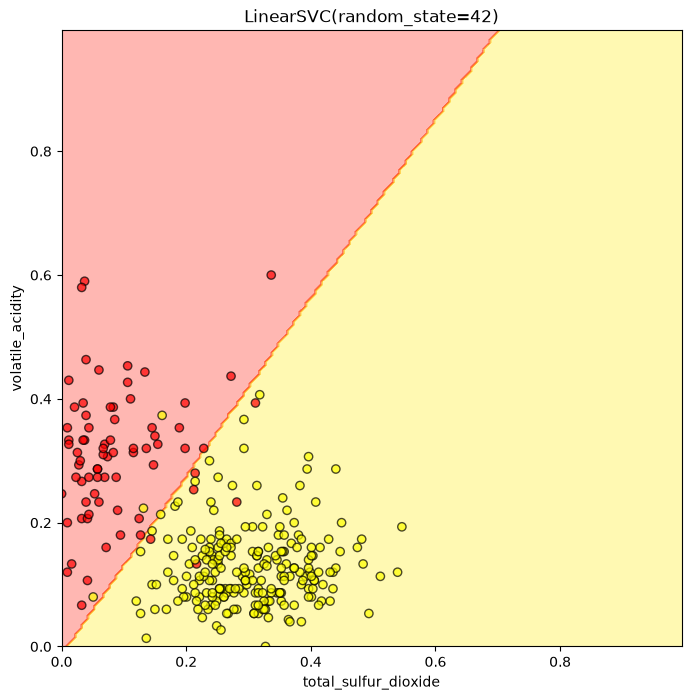

In [15]:
# для проверки: функция с LinearSVC даёт тот же график, что и в вопросе 2
plot_decision_boundary(LinearSVC(random_state=42), X, y)

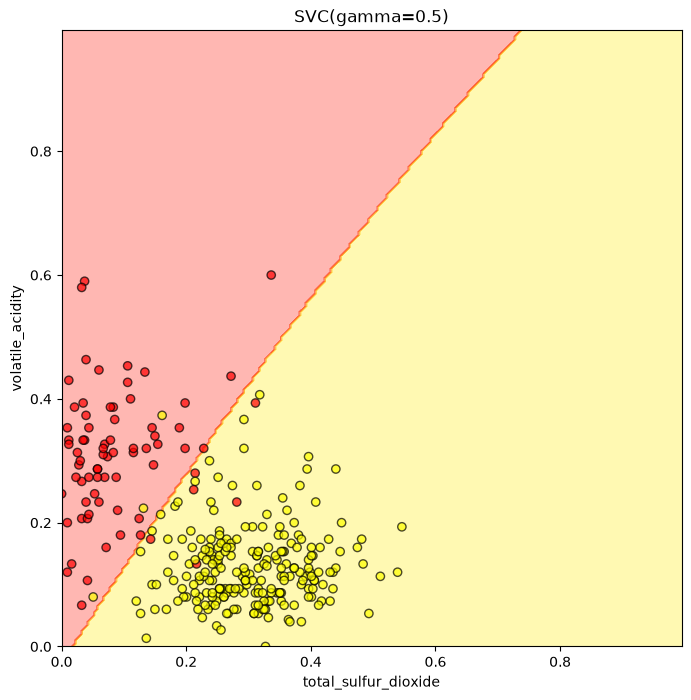

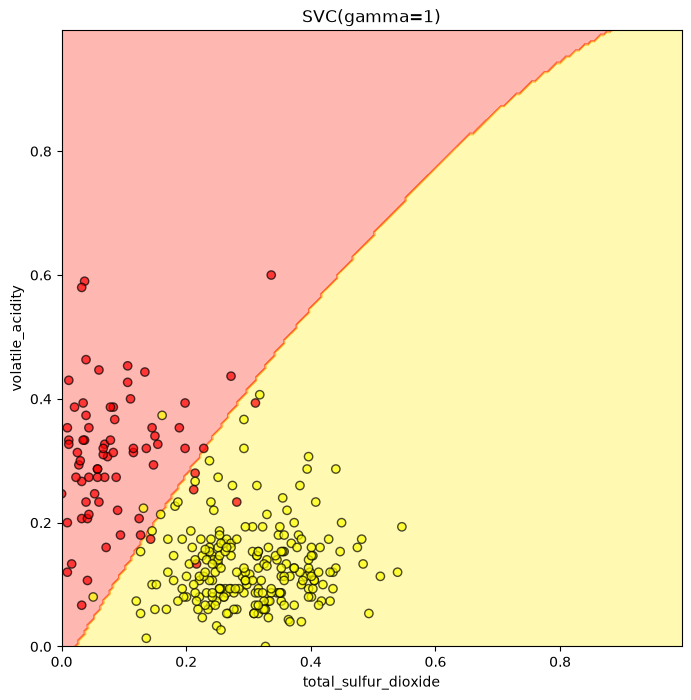

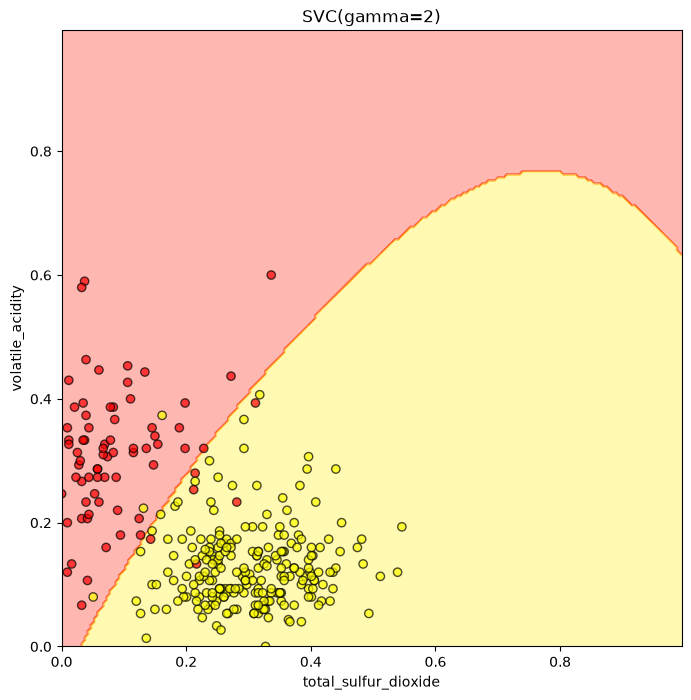

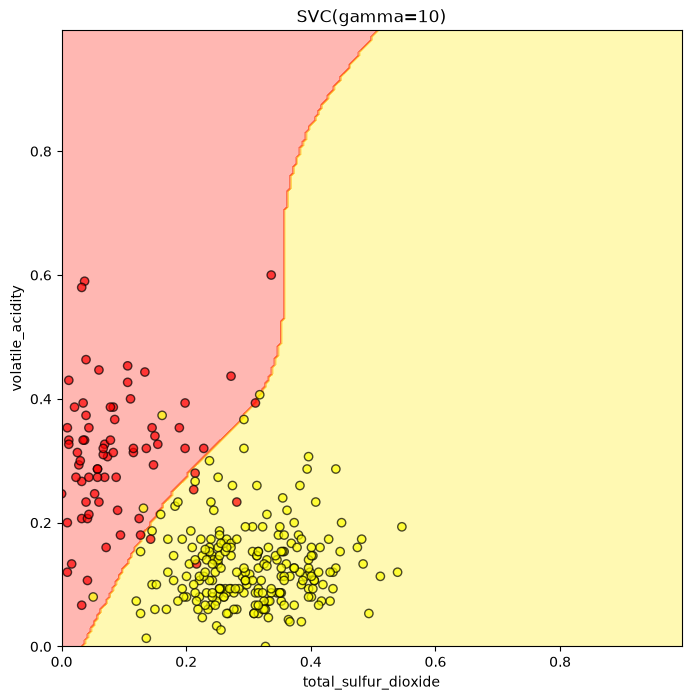

In [16]:
# гауссово ядро (rbf) при разных значениях gamma, C = 1
gammas = [.5, 1, 2, 10]

for gamma in gammas:
    SVC_Gaussian = SVC(kernel='rbf', gamma=gamma)
    plot_decision_boundary(SVC_Gaussian, X, y)

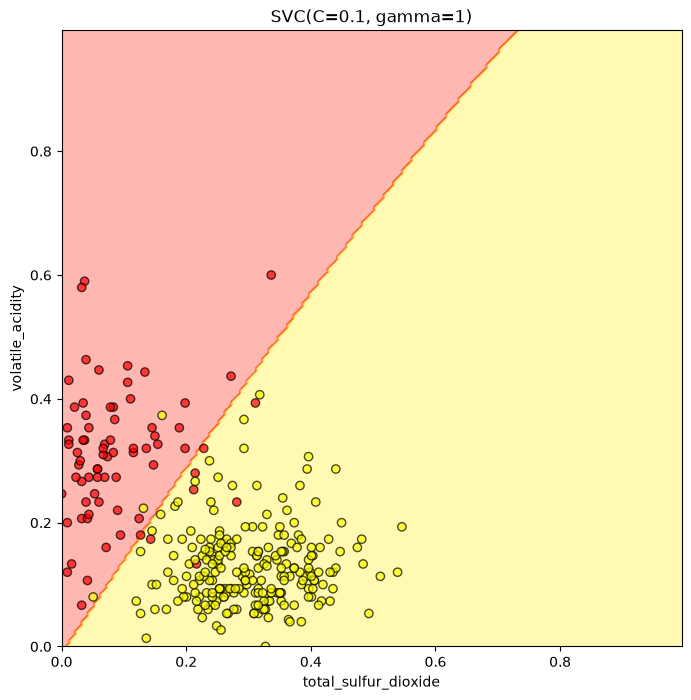

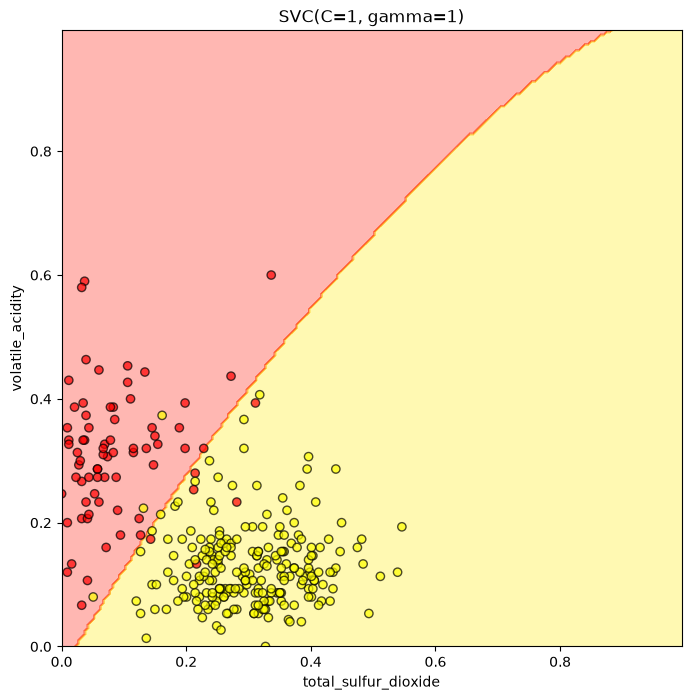

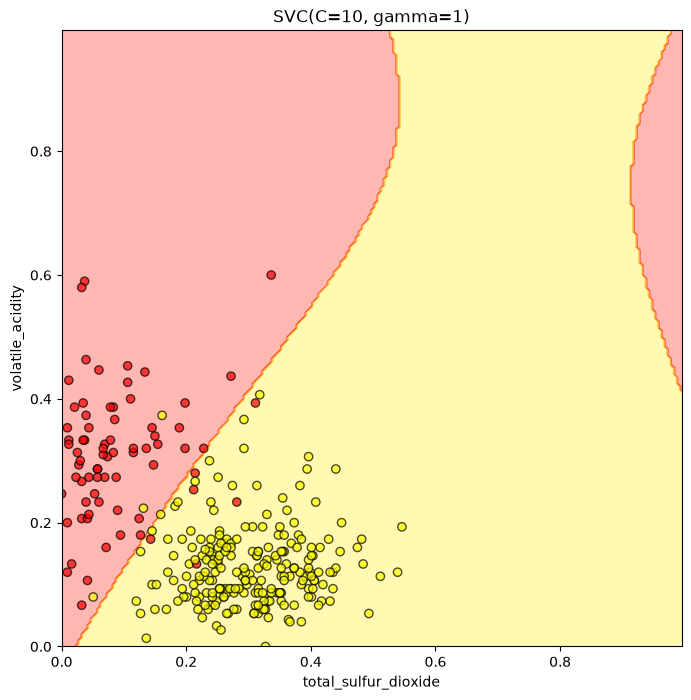

In [17]:
# gamma фиксируем (gamma = 1), меняем C
Cs = [.1, 1, 10]

for C in Cs:
    SVC_Gaussian = SVC(kernel='rbf', gamma=1, C=C)
    plot_decision_boundary(SVC_Gaussian, X, y)

**Что сделано (Вопрос 3):** объединили код из вопроса 2 в функцию `plot_decision_boundary(estimator, X, y)`, которая принимает любую модель, обучает её, берёт 300 точек и рисует границу решения. Затем построили границы для SVC с гауссовым ядром.

* При увеличении `gamma` граница становится всё более извилистой и подстраивается под отдельные точки (при `gamma = 10` модель склонна к переобучению), при малых `gamma` граница гладкая.
* При увеличении `C` регуляризация ослабевает: модель сильнее штрафуется за ошибки на обучающих данных, и граница становится более сложной; при малом `C` она более гладкая и допускает больше ошибок.

## Вопрос 4

В этом вопросе мы сравним время установки между SVC и Nystroem с ядром rbf.  
<br><br>
Jupyter Notebooks предоставляет полезную магическую функцию **`%timeit`** которая выполняет строку и отпечатывает время, необходимое для установки. Если вы введете **`%timeit`** в начале ячейки, то она запустит всю ячейку и отобразит время выполнения.

* Повторно загрузите данные о качестве вина, если вы внесли изменения в оригинал.
* Создайте `y` из data.color и `X` из остальных столбцов.
* Используйте `%%timeit` чтобы получить время для настройки SVC с ядром rbf.
* Используйте `%%timeit` для получения времени для следующего: упорядочите данные с помощью Nystroem, а затем встроите SGD-классификатор.

Nystroem+SGD потребуется гораздо меньше времени для установки. Эта разница будет более выраженной, если набор данных был больше.

* Сделайте 5 копий X и свяжите их
* Сделайте 5 копий у и свяжите их
* Сравните время, необходимое для соответствия обоим методам выше.

In [19]:
# заново загружаем данные
data = pd.read_csv('data/Wine_Quality_Data.csv')

y = (data['color'] == 'red').astype(int)
X = data.drop(columns='color')

# масштабируем признаки, чтобы ядро rbf работало корректно
X = MinMaxScaler().fit_transform(X)
X.shape

(6497, 12)

In [ ]:
%%timeit
svc = SVC(kernel='rbf', gamma=.5, C=1).fit(X, y)

96 ms ± 3 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


In [ ]:
%%timeit
nystroem = Nystroem(kernel='rbf', gamma=.5, n_components=100, random_state=42)
X_transformed = nystroem.fit_transform(X)
sgd = SGDClassifier(random_state=42).fit(X_transformed, y)

57 ms ± 10 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


Теперь увеличим набор данных в 5 раз и сравним время обучения ещё раз.

In [ ]:
# 5 копий X и y
X_big = np.concatenate([X] * 5)
y_big = np.concatenate([y] * 5)
X_big.shape, y_big.shape

((32485, 12), (32485,))

In [ ]:
%%timeit
svc = SVC(kernel='rbf', gamma=.5, C=1).fit(X_big, y_big)

1.68 s ± 124 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


In [ ]:
%%timeit
nystroem = Nystroem(kernel='rbf', gamma=.5, n_components=100, random_state=42)
X_transformed = nystroem.fit_transform(X_big)
sgd = SGDClassifier(random_state=42).fit(X_transformed, y_big)

149 ms ± 1 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


**Что сделано (Вопрос 4):** заново загрузили данные, взяли `y` из цвета вина, а `X` - из остальных столбцов (с масштабированием `MinMaxScaler`). С помощью `%%timeit` измерили время обучения `SVC` с ядром rbf и связки `Nystroem` + `SGDClassifier`. Потом увеличили данные в 5 раз (5 копий `X` и `y`) и измерили снова. `SVC` с ядром сильно замедляется при росте данных (сложность растёт быстрее, чем линейно), а `Nystroem` + `SGD` остаётся быстрым, так как приближает ядро небольшим числом компонент и использует линейную модель.